In [4]:
from wget import download
from os import path, listdir

# descargamos una base de datos en Excel
if not path.exists("catalogo_streaming_argentina_2024.xlsx"):
  download("https://ignaciorlando.github.io/datasets/data-science/catalogo_streaming_argentina_2024.xlsx")
else:
  print("No vamos a bajar el archivo excel porque ya existe!")



No vamos a bajar el archivo excel porque ya existe!


In [45]:
import pandas as pd
dataset_streaming = pd.read_excel("catalogo_streaming_argentina_2024.xlsx")
dataset_streaming = dataset_streaming.dropna()

In [46]:
print(dataset_streaming.columns)

Index(['title', 'platform', 'type', 'imdbVotes', 'imdbScore', 'tmdbPopularity',
       'tmdbScore', 'runtime', 'genres', 'director', 'year_range', 'url'],
      dtype='str')


# Boxs Plot del histograma para ver la concentracion

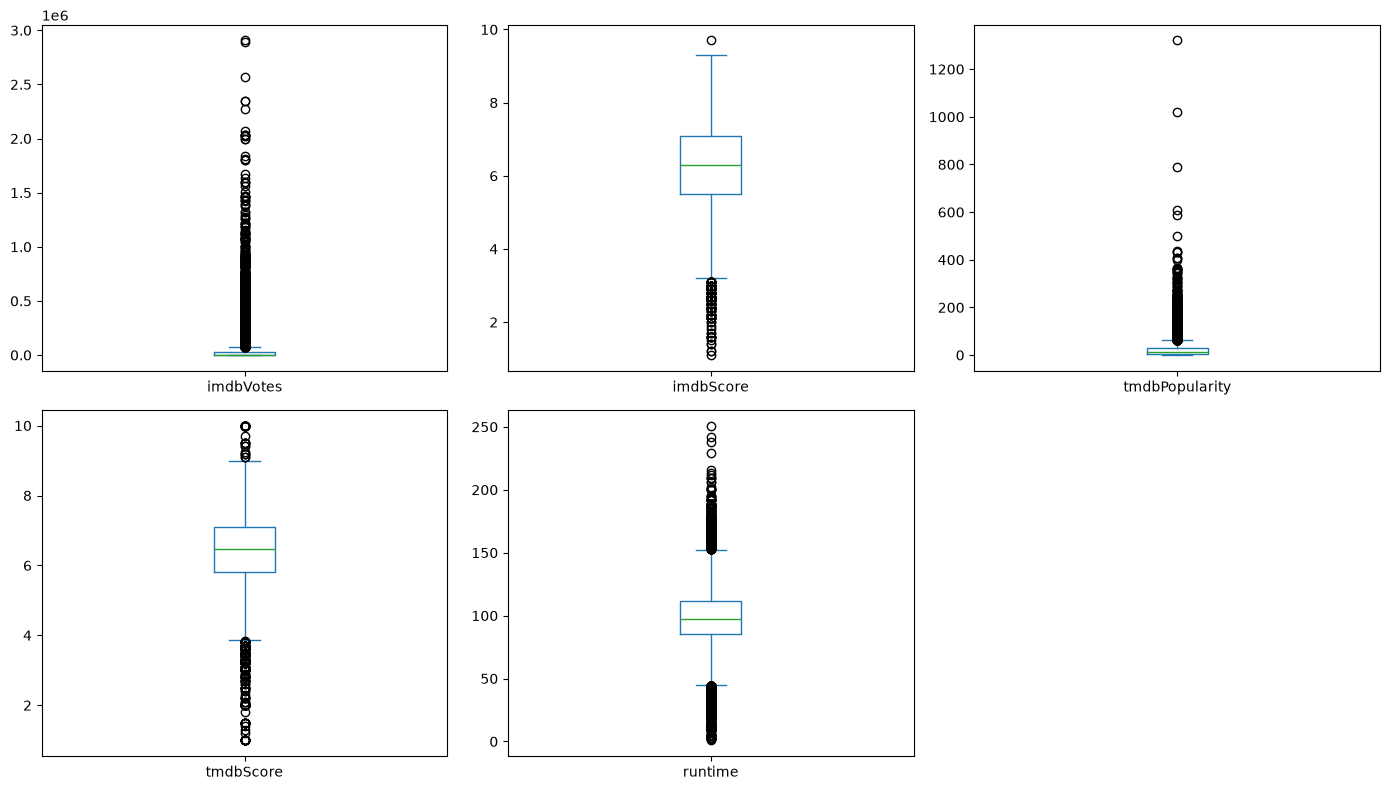

In [47]:
import matplotlib.pyplot as plt
dataset_streaming.plot(
    kind='box',
    subplots=True,
    layout=(2,3),
    figsize=(14, 8)
)

plt.tight_layout()
plt.show()

# Tabla de la distribucion

In [48]:
dataset_streaming.describe()

,imdbVotes,imdbScore,tmdbPopularity,tmdbScore,runtime
count,1.297900e+04,12979.000000,12979.000000,12979.000000,12979.000000
mean,5.763986e+04,6.233069,24.156631,6.361406,96.975653
std,1.645003e+05,1.159259,37.994831,1.112202,28.862752
min,5.000000e+00,1.100000,0.081000,1.000000,1.000000
25%,6.665000e+02,5.500000,5.719500,5.800000,85.000000
50%,3.691000e+03,6.300000,13.629000,6.468000,97.000000
75%,3.029900e+04,7.100000,28.194000,7.100000,112.000000
max,2.906253e+06,9.700000,1320.405000,10.000000,251.000000


# Histograma por columnas

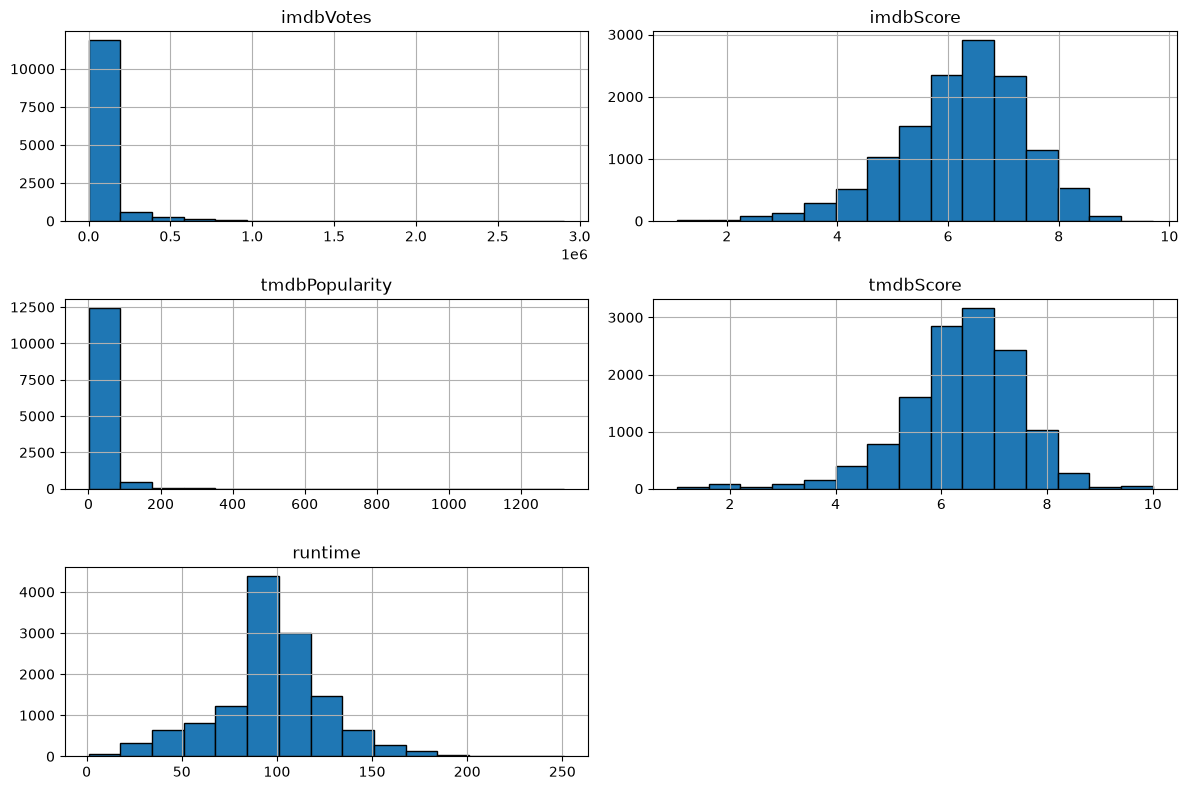

In [49]:

import matplotlib.pyplot as plt

# 2. Generar histogramas para TODAS las columnas numéricas
dataset_streaming.hist(figsize=(12, 8), bins=15, edgecolor='black')

# 3. Ajustar los espacios y mostrar el gráfico
plt.tight_layout()
plt.show()

# Analisis
* Se puede observervar la distribucion de imdbvotes muy cercana al 0, lo que en describe, por tener mucho datos acotados a la derecha muy lejanos, podemos dar una idea que el 50% esta muy debajo de la media, ya que al tener datos extremos, la media aumenta 50% = 2,84 media = 4,83
* tmdb Popularity tambien hace lo mismo, por sus extremos tan lejanos nos dice que la media esta alejada del 50% que es mucho menor, 50% = 14 media = 41
* imbdb Score tiene una distribucion de campana normal, lo que da como significado que la media y la mediana se parecen y no deben de estar alejadas,
  50% = 6.60 media = 6,46
* tmdb Score: Pasa lo mismo con imdb Score, usando la distribucion parecida a campana obteniendo valores similares
* runtime: Parecer tener una cola derecha pronunciada, donde los valores se rigen por el valor 100, esto marca que la mediana sera mas abajo que la media osea 50% = 89 y media= 80

# Hipotesis
Mientras mas popularidad, mas puntuacion tendra

In [50]:
import numpy as np
from scipy import stats

variable_2 = "tmdbPopularity"
variable_1 = "tmdbScore"

# Extraer las columnas del DataFrame
datos_columna1 = dataset_streaming[variable_1]
datos_columna2 = dataset_streaming[variable_2]

# calcular la correlación de Pearson usando NumPy
#coeficiente_correlacion = np.corrcoef(datos_columna1, datos_columna2)[0, 1]
#print(coeficiente_correlacion)

# alternativamente, se puede usar SciPy:
coeficiente_correlacion, _ = stats.pearsonr(datos_columna1, datos_columna2)
print(f"Correlación entre {variable_1} y {variable_2}: {coeficiente_correlacion:.4f}")

Correlación entre tmdbScore y tmdbPopularity: 0.2515


C:\Users\mateo\AppData\Local\Temp\ipykernel_16480\1040880256.py:18: DeprecationWarning: Please import `pearsonr` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  coeficiente_correlacion, _ = stats.pearsonr(dataset_streaming[variable_1], dataset_streaming[variable_2])


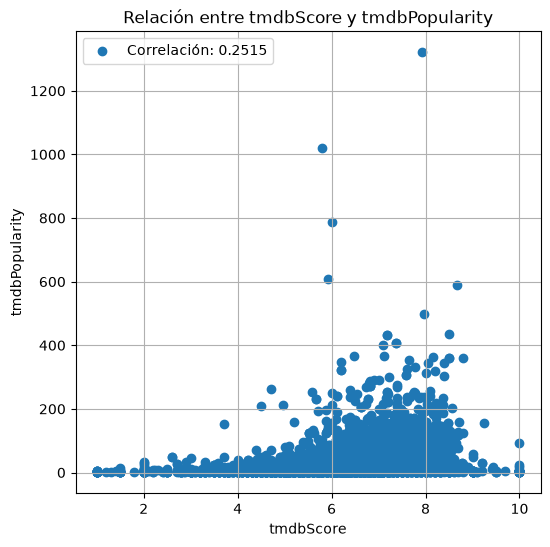

In [51]:
from scipy.stats import stats
import matplotlib.pyplot as plt

variable_2 = "tmdbPopularity"
variable_1 = "tmdbScore"
# en clase, mostrar también este ejemplo
#variable_1 = "CHAS"
#variable_2 = "NOX"

# creamos el scatter plot
plt.figure(figsize=(6, 6))  # con esta línea podemos ajustar el tamaño de la gráfica
plt.scatter(dataset_streaming[variable_1], dataset_streaming[variable_2])
plt.xlabel(variable_1)
plt.ylabel(variable_2)
plt.title("Relación entre {} y {}".format(variable_1, variable_2))

# calcular la correlación de Pearson usando SciPy
coeficiente_correlacion, _ = stats.pearsonr(dataset_streaming[variable_1], dataset_streaming[variable_2])
# agregar la leyenda con el valor del coeficiente de correlación
plt.legend([f"Correlación: {coeficiente_correlacion:.4f}"], loc="upper left")

# Mostrar el gráfico
plt.grid(True)
plt.show()

Hipotesis falsa, no tiene correlacion

# Matriz de correlacion

In [52]:
# calculamos las correlaciones entre features e imprimimos la matriz
correlation_matrix = dataset_streaming.corr(numeric_only=True)
correlation_matrix

,imdbVotes,imdbScore,tmdbPopularity,tmdbScore,runtime
imdbVotes,1.000000,0.286000,0.424565,0.241996,0.290543
imdbScore,0.286000,1.000000,0.173280,0.608964,0.027250
tmdbPopularity,0.424565,0.173280,1.000000,0.251525,0.074362
tmdbScore,0.241996,0.608964,0.251525,1.000000,0.053380
runtime,0.290543,0.027250,0.074362,0.053380,1.000000


## Mapa de calor de las correlaciones

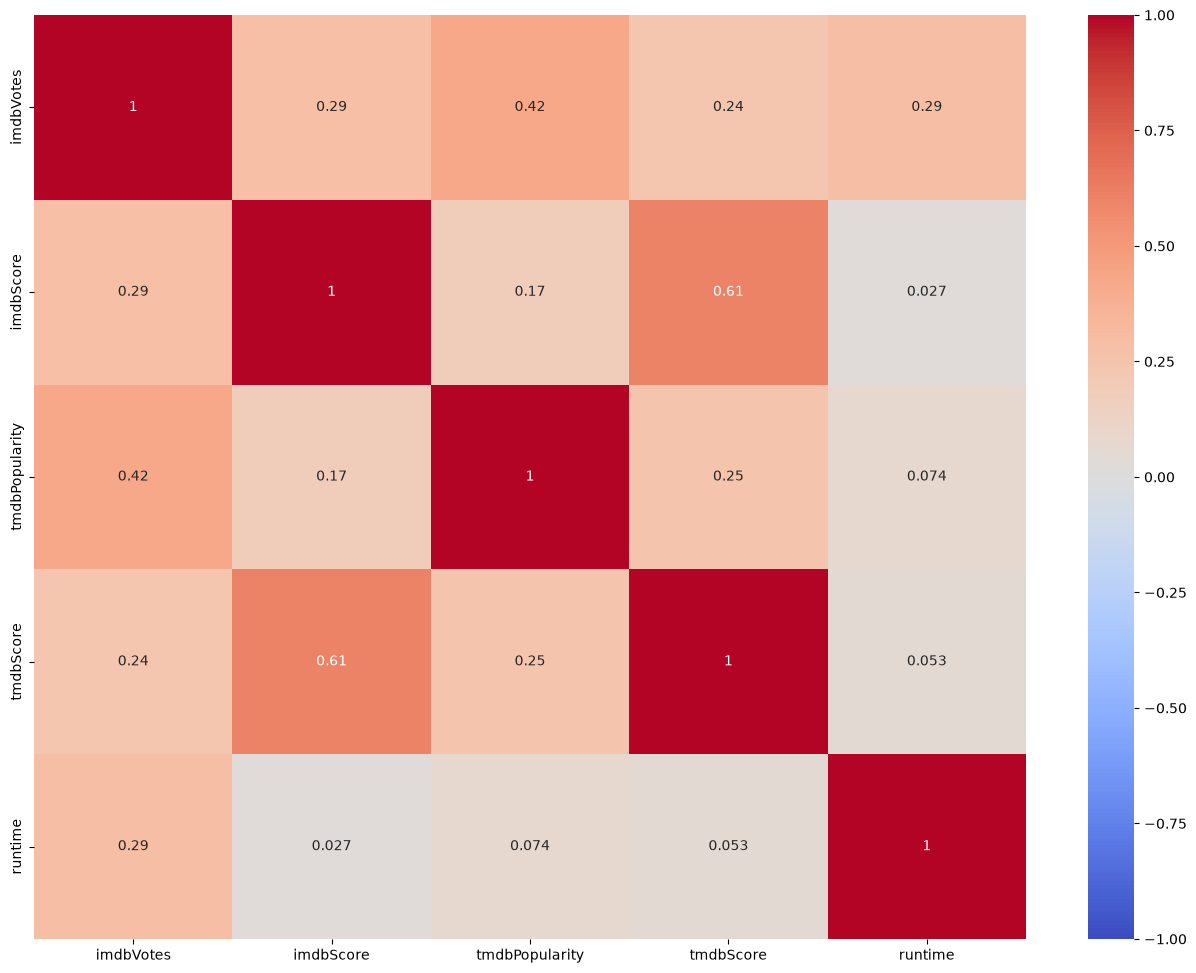

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt

# imprimimos la matriz como un heatmap
plt.figure(figsize=(16,12))
sns.heatmap(correlation_matrix, vmin=-1.0, vmax=1.0, center=0.0, annot=True, cmap= 'coolwarm')
plt.show()

## Mapa de quien cumple la correlacion osea >0,7

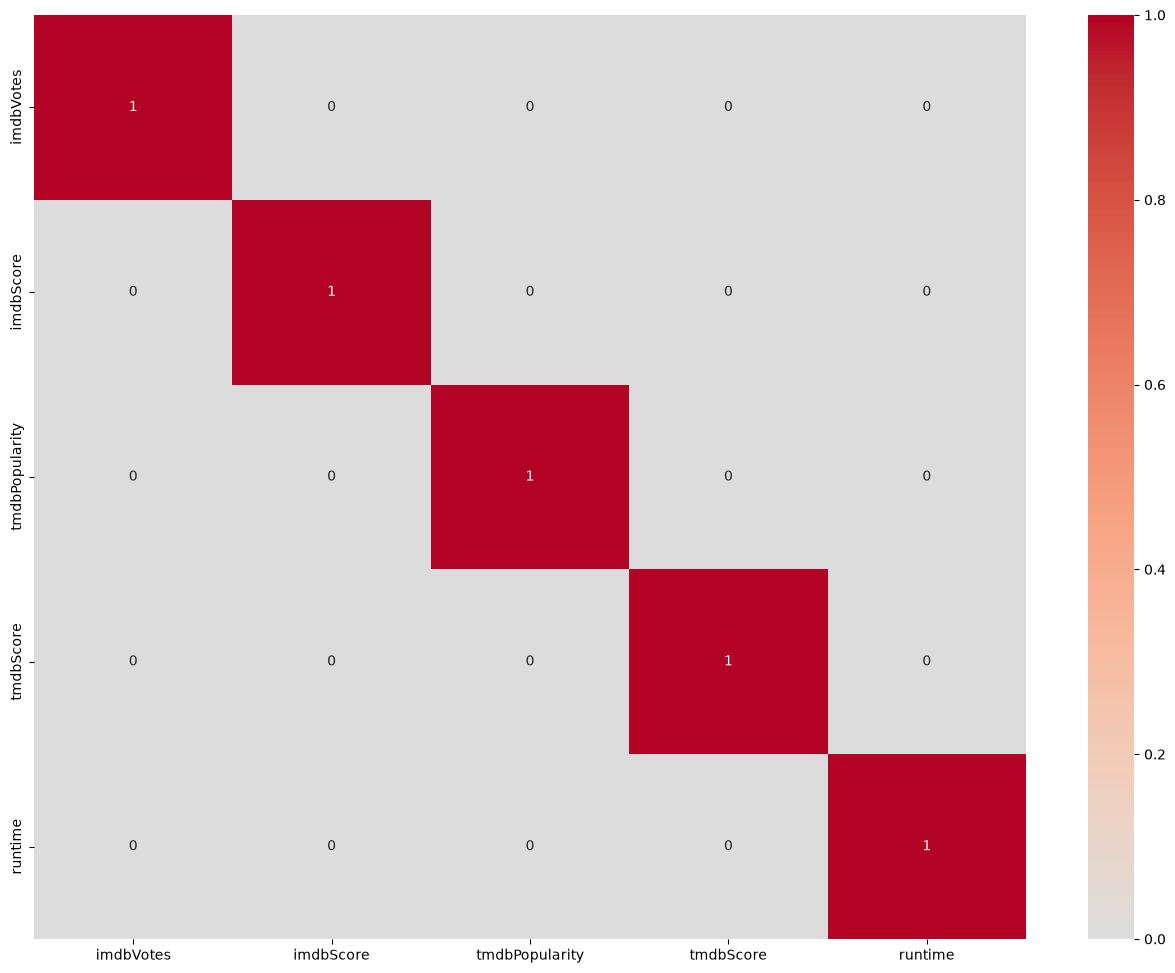

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns # Asumiendo que usas seaborn para el heatmap
correlation_matrix_umbralizada = (correlation_matrix.abs() > 0.7).astype(int)

# Ahora el array es modificable y podemos llenar la diagonal con 0



plt.figure(figsize=(16,12))
sns.heatmap(correlation_matrix_umbralizada, vmin=0.0, vmax=1.0, center=0.0, annot=True, cmap= 'coolwarm')
plt.show()

## Deberia imprimirse un scatter plot, pero modifique para que no esten la diagonal, como no hay correlaciones no imprime nada

In [59]:
# iteramos por cada una de las columnas
for i, col in enumerate(correlation_matrix_umbralizada.columns):
  # y por cada una de las filas (para eso usamos el índice)
  for j in range(i,len(correlation_matrix_umbralizada.index)):
    # extraemos el nombre de la fila en la que estamos
    row = correlation_matrix_umbralizada.index[j]
    # si en esa posición tenemos un True en la matriz umbralizada
    if correlation_matrix_umbralizada.loc[row, col] and row != col:
      # nos traemos el valor de esa correlación
      correlation = correlation_matrix.loc[row, col]
      # representamos en un scatter plot cuadrado los valores de ambas variables
      plt.figure(figsize=(6, 6))
      plt.scatter(dataset_streaming[row], dataset_streaming[col])
      # y lo mostramos bonito
      plt.title(f"Scatter plot entre {col} y {row} - r = {correlation:.4f}")
      plt.xlabel(row)
      plt.ylabel(col)
      plt.grid(True)
      plt.show()